# 🧪 Prática (Gabarito): Construindo sua Primeira Rede Neural com PyTorch (Dataset Iris)

Nesta atividade prática, você vai construir e treinar sua primeira rede neural com **PyTorch** do zero no Google Colab, seguindo o passo a passo que aprendemos na **Aula 02**.

---
## Passo 1: Download do Dataset no Colab

Execute a célula abaixo para baixar o dataset **Iris** diretamente do Kaggle.

In [1]:
import kagglehub

path = kagglehub.dataset_download("uciml/iris")
print("Path to dataset files:", path)

  0%|                                              | 0.00/3.60k [00:00<?, ?B/s]

100%|█████████████████████████████████████| 3.60k/3.60k [00:00<00:00, 8.62MB/s]

Extracting files...


Path to dataset files: /home/allan/.cache/kagglehub/datasets/uciml/iris/versions/2


---
## Passo 2: Leitura e Exploração do CSV com Pandas

1. Importe `os` e `pandas`.
2. Liste os arquivos dentro da pasta `path` (o arquivo se chama `Iris.csv`).
3. Carregue o arquivo `Iris.csv` em um DataFrame `df` e exiba as primeiras linhas com `df.head()`.

In [2]:
import os
import pandas as pd

print("Arquivos na pasta:", os.listdir(path))

csv_path = os.path.join(path, "Iris.csv")
df = pd.read_csv(csv_path)
df.head()

Arquivos na pasta: ['database.sqlite', 'Iris.csv']


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


---
## Passo 3: Preparação das Entradas (`X`) e do Alvo (`Y`) em Tensores

1. Importe o `torch`.
2. Crie uma coluna binária para a espécie alvo (por exemplo, `1` se `Species == "Iris-setosa"` e `0` caso contrário) para usarmos a mesma estrutura de classificação binária da Aula 02.
3. Selecione as **4 colunas numéricas** (`SepalLengthCm`, `SepalWidthCm`, `PetalLengthCm`, `PetalWidthCm`) e converta para um tensor `X` do tipo `torch.float32`.
4. Converta a coluna alvo para um tensor `Y_real` do tipo `torch.float32` com formato `(N, 1)` usando `.unsqueeze(1)`.

In [3]:
import torch

torch.manual_seed(42)

# 1 se for Iris-setosa, 0 caso contrário
df["Alvo"] = (df["Species"] == "Iris-setosa").astype(int)

colunas_entrada = ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]
X = torch.tensor(df[colunas_entrada].values, dtype=torch.float32)
Y_real = torch.tensor(df["Alvo"].values, dtype=torch.float32).unsqueeze(1)

print("Formato de X:", X.shape)
print("Formato de Y_real:", Y_real.shape)

Formato de X: torch.Size([150, 4])
Formato de Y_real: torch.Size([150, 1])


---
## Passo 4: Construindo a Arquitetura da Rede (`nn.Module`)

1. Importe `torch.nn as nn`.
2. Crie uma classe herdando de `nn.Module` (ex: `class RedeIris(nn.Module):`).
3. No método `__init__`, defina:
   - Uma camada oculta linear que receba **4 entradas** e tenha **8 neurônios** (`nn.Linear(4, 8)`), seguida da ativação `nn.ReLU()`.
   - Uma camada de saída linear que receba **8 entradas** e tenha **1 neurônio** (`nn.Linear(8, 1)`), seguida da ativação `nn.Sigmoid()`.
4. No método `forward(self, x)`, passe `x` pela camada oculta + ReLU e depois pela camada de saída + Sigmoid.
5. Instancie o seu `modelo`.

In [4]:
import torch.nn as nn

class RedeIris(nn.Module):
    def __init__(self):
        super(RedeIris, self).__init__()
        self.camada_oculta = nn.Linear(in_features=4, out_features=8)
        self.relu = nn.ReLU()
        self.camada_saida = nn.Linear(in_features=8, out_features=1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        h = self.relu(self.camada_oculta(x))
        out = self.sigmoid(self.camada_saida(h))
        return out

modelo = RedeIris()
print(modelo)

RedeIris(
  (camada_oculta): Linear(in_features=4, out_features=8, bias=True)
  (relu): ReLU()
  (camada_saida): Linear(in_features=8, out_features=1, bias=True)
  (sigmoid): Sigmoid()
)


---
## Passo 5: Função de Perda (Loss) e Otimizador

1. Importe `torch.optim as optim`.
2. Defina a função de perda `criterio = nn.BCELoss()`.
3. Defina o otimizador (`optim.SGD` ou `optim.Adam`) passando `modelo.parameters()` e uma taxa de aprendizado (`lr`).

In [5]:
import torch.optim as optim

criterio = nn.BCELoss()
otimizador = optim.SGD(modelo.parameters(), lr=0.05)

---
## Passo 6: Loop de Treinamento (Os 5 Passos do PyTorch)

Crie uma lista `historico_perda = []` e faça um laço `for` por um número de épocas (ex: `200` épocas) executando os **5 passos**:
1. Zerar os gradientes acumulados (`otimizador.zero_grad()`)
2. Fazer o Forward Pass (`predicoes = modelo(X)`)
3. Calcular o erro (`perda = criterio(predicoes, Y_real)`) e guardar `perda.item()` na lista
4. Calcular os gradientes via Backpropagation (`perda.backward()`)
5. Atualizar os pesos da rede (`otimizador.step()`)

In [6]:
epocas = 200
historico_perda = []

for epoca in range(epocas):
    # 1. Zerar os gradientes acumulados
    otimizador.zero_grad()

    # 2. Forward Pass
    predicoes = modelo(X)

    # 3. Calcular o erro (Loss)
    perda = criterio(predicoes, Y_real)
    historico_perda.append(perda.item())

    # 4. Backpropagation (Autograd)
    perda.backward()

    # 5. Atualizar os pesos
    otimizador.step()

    if (epoca + 1) % 40 == 0:
        print(f"Época {epoca+1:03d}/{epocas} - Loss: {perda.item():.4f}")

Época 040/200 - Loss: 0.2562
Época 080/200 - Loss: 0.0907
Época 120/200 - Loss: 0.0459
Época 160/200 - Loss: 0.0290
Época 200/200 - Loss: 0.0206


---
## Passo 7: Gráfico da Curva de Aprendizado e Acurácia

1. Plote a lista `historico_perda` usando `matplotlib.pyplot` para verificar se o erro caiu ao longo das épocas.
2. Usando `with torch.no_grad():`, calcule as previsões finais (`prob >= 0.5`) e exiba a **acurácia** da sua rede!

Acurácia Final no Dataset Iris: 100.00%


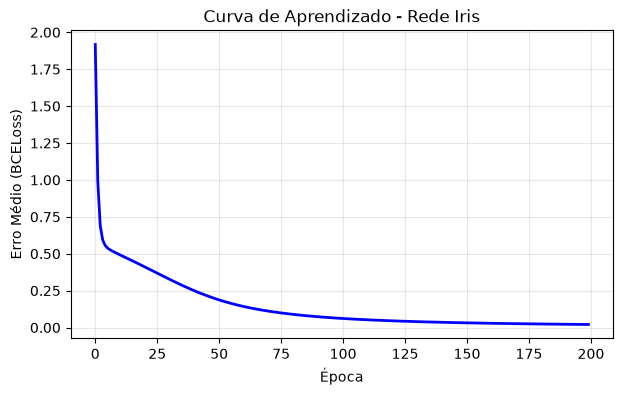

In [7]:
import matplotlib.pyplot as plt

with torch.no_grad():
    prob = modelo(X)
    classes_preditas = (prob >= 0.5).float()
    acuracia = (classes_preditas == Y_real).float().mean() * 100

print(f"Acurácia Final no Dataset Iris: {acuracia.item():.2f}%")

plt.figure(figsize=(7, 4))
plt.plot(historico_perda, color="blue", linewidth=2)
plt.xlabel("Época")
plt.ylabel("Erro Médio (BCELoss)")
plt.title("Curva de Aprendizado - Rede Iris")
plt.grid(True, alpha=0.3)
plt.show()